<a href="https://colab.research.google.com/github/snatzehua/bt-4012-project-2026/blob/feat--zs-exploration-00/notebooks/04_class_imbalance_treatment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BT4012 · 04 · Class-imbalance treatment (Experiment B)

**Question:** does changing the training loss or class distribution improve fraud ranking at the same false-positive allowance / review capacity?

Stage A selected **all history (months 0–4)**: mean validation AP 0.18567 and recall at 5% FPR 54.36%. Recent windows did not consistently beat same-size historical samples. We now freeze the eligible training period and LightGBM configuration, and vary only the imbalance-treatment policy.

Compare no treatment, moderate/full positive-class weighting, and random majority undersampling at three ratios. Six conditions × three paired seeds = **18 fits**. Validation remains month 5 at its original prevalence. Months 6–7 are excluded from modelling and evaluation.

Run top to bottom after `00_data_preparation.ipynb`. Stage A model files are not needed. Use Colab CPU or your existing local environment. No outputs are pre-filled.


## 1. Paths and prerequisites

Colab reads `MyDrive/BT4012_grp_proj/processed/baf_clean.parquet` and `preparation_manifest.json`. Locally, put this notebook in `notebooks/`; the prepared pair belongs in `data/processed/`. Keep the same paths used in preparation and baseline modelling. The raw CSV is not needed here.


In [ ]:
import sys
from pathlib import Path

# Detect the runtime; local execution does not require google.colab.
IN_COLAB = 'google.colab' in sys.modules

# Colab: keep Base.csv directly inside this existing Drive project folder.
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/BT4012_grp_proj')

# Local: normally leave None; set an absolute repo path if auto-detection fails.
LOCAL_REPO_ROOT = None

if IN_COLAB:
    from google.colab import drive

    drive.mount('/content/drive')
    PROJECT_DIR = DRIVE_PROJECT_DIR
    RAW_PATH = PROJECT_DIR / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'processed'
else:
    if LOCAL_REPO_ROOT is not None:
        PROJECT_DIR = Path(LOCAL_REPO_ROOT).expanduser().resolve()
    else:
        working_dir = Path.cwd().resolve()
        candidates = [working_dir, *working_dir.parents]
        PROJECT_DIR = next(
            (
                candidate
                for candidate in candidates
                if (candidate / 'notebooks').is_dir()
                and (candidate / 'data').is_dir()
            ),
            working_dir,
        )

    RAW_PATH = PROJECT_DIR / 'data' / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'

CLEAN_PATH = PROCESSED_DIR / 'baf_clean.parquet'
MANIFEST_PATH = PROCESSED_DIR / 'preparation_manifest.json'

print('Runtime:', 'Google Colab' if IN_COLAB else 'Local Python')
print('Project:', PROJECT_DIR)
print('Raw CSV:', RAW_PATH)
print('Prepared data:', CLEAN_PATH)


Mounted at /content/drive
Runtime: Google Colab
Project: /content/drive/MyDrive/BT4012_grp_proj
Raw CSV: /content/drive/MyDrive/BT4012_grp_proj/Base.csv
Prepared data: /content/drive/MyDrive/BT4012_grp_proj/processed/baf_clean.parquet


## 2. Fixed settings and bounded search

Keep seeds `[42, 43, 44]` for the reported comparison. Within each seed, all treatments use the same model seed. Undersampling adds sampling randomness; seed spread is not uncertainty across independent months.

The baseline is refitted here so comparisons use the same runtime and evaluation code. With unchanged data, dependencies and configuration, its seed-42 AP should be close to the previous 0.18499. Investigate a substantial discrepancy rather than mixing incompatible runs.

`SAVE_MODELS=False` avoids storing 18 models. Validation predictions and training row IDs are saved by default. Small result tables are checkpointed after each completed fit. Restarting creates a new run; it does not automatically resume partial fits.


In [ ]:
import importlib.util
import subprocess

required_packages = {'lightgbm': 'lightgbm>=4.0', 'pyarrow': 'pyarrow>=14.0'}
missing_packages = [
    package for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]

if missing_packages:
    if IN_COLAB:
        subprocess.check_call([
            sys.executable, '-m', 'pip', 'install', '-q', *missing_packages,
        ])
    else:
        raise ImportError('Missing dependencies. Run: python -m pip install -r requirements.txt')

import hashlib
import json
import platform
import time
import warnings
from datetime import datetime, timezone
from uuid import uuid4

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder


SEEDS = [42, 43, 44]
N_JOBS = 2
VERIFY_CHECKSUM = True
SAVE_MODELS = False
SAVE_PREDICTIONS = True
SAVE_TRAIN_IDS = True
FPR_TARGET = 0.05
REVIEW_CAPACITIES = [0.01, 0.02, 0.05]
NEGATIVES_PER_POSITIVE = [20, 10, 1]
TRAIN_MONTHS = [0, 1, 2, 3, 4]
VALIDATION_MONTHS = [5]
LGBM_TREES = 300
FIXED_PARAMS = {'num_leaves': 15, 'min_child_samples': 100}
RUN_LABEL = 'imbalance_all_history'

assert len(SEEDS) == len(set(SEEDS)) and len(SEEDS) > 0
assert all(ratio >= 1 for ratio in NEGATIVES_PER_POSITIVE)

run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
RUN_NAME = f'{RUN_LABEL}_{run_id}'
RESULTS_DIR = PROJECT_DIR / 'results' / 'imbalance_treatment' / RUN_NAME
ARTIFACTS_DIR = PROJECT_DIR / 'artifacts' / 'imbalance_treatment' / RUN_NAME
FIGURES_DIR = RESULTS_DIR / 'figures'

for directory in [RESULTS_DIR, FIGURES_DIR, ARTIFACTS_DIR]:
    directory.mkdir(parents=True, exist_ok=False)

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 200,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

print('Results:', RESULTS_DIR)
print('Artifacts:', ARTIFACTS_DIR)
print('Planned fits:', (3 + len(NEGATIVES_PER_POSITIVE)) * len(SEEDS))


Results: /content/drive/MyDrive/BT4012_grp_proj/results/imbalance_treatment/imbalance_all_history_20261115T182353Z_5d20b0
Artifacts: /content/drive/MyDrive/BT4012_grp_proj/artifacts/imbalance_treatment/imbalance_all_history_20261115T182353Z_5d20b0
Planned fits: 18


## 3. Load only development months

The manifest defines the shared feature schema and deterministic missing-value decoding established in preparation. We reuse that schema across conditions, including the training-history constant-feature exclusion. We do **not** refit global feature selection for individual windows. All learned model preprocessing is fitted separately inside each condition.

The optional checksum reads file bytes for integrity; it does not evaluate held-out labels. Parquet filtering below loads only months 0–5 into the modelling dataframe.


In [ ]:
def file_sha256(path):
    """Return a chunked SHA-256 digest to verify the prepared file matches its manifest."""
    digest = hashlib.sha256()

    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)

    return digest.hexdigest()


if not CLEAN_PATH.is_file() or not MANIFEST_PATH.is_file():
    raise FileNotFoundError('Run 00_data_preparation.ipynb first with the same project paths.')

with open(MANIFEST_PATH, encoding='utf-8') as handle:
    manifest = json.load(handle)

if manifest.get('schema_version') != 1:
    raise ValueError('Unsupported preparation manifest version.')

if VERIFY_CHECKSUM and file_sha256(CLEAN_PATH) != manifest['prepared_sha256']:
    raise ValueError('Parquet fingerprint differs from the manifest; rerun preparation.')


TARGET = manifest['target']
MONTH = manifest['month_column']
ROW_ID = manifest['row_id_column']
FEATURES = manifest['features']
NUMERICAL = manifest['numerical_features']
CATEGORICAL = manifest['categorical_features']

if manifest['split_months']['train'] != TRAIN_MONTHS:
    raise ValueError('This experiment expects training months 0–4.')

if manifest['split_months']['validation'] != VALIDATION_MONTHS:
    raise ValueError('This experiment expects validation month 5.')

if set(FEATURES) != set(NUMERICAL + CATEGORICAL):
    raise ValueError('Inconsistent feature lists in preparation manifest.')

if set(FEATURES) & {TARGET, MONTH, ROW_ID}:
    raise ValueError('Target, month or row ID cannot be predictors.')

df = pd.read_parquet(
    CLEAN_PATH,
    filters=[(MONTH, 'in', TRAIN_MONTHS + VALIDATION_MONTHS)],
)

if list(df.columns) != manifest['columns'] or not df[ROW_ID].is_unique:
    raise ValueError('Prepared schema or row identifiers are inconsistent.')

for column in CATEGORICAL:
    df[column] = df[column].astype(object).where(df[column].notna(), np.nan)

# Sort by original row ID to make sampling reproducible if parquet row order changes.
history = df[df[MONTH].isin(TRAIN_MONTHS)].sort_values(ROW_ID).reset_index(drop=True)
validation = df[df[MONTH].isin(VALIDATION_MONTHS)].sort_values(ROW_ID).reset_index(drop=True)
del df

for name, frame in [('train', history), ('validation', validation)]:
    if len(frame) != manifest['split_counts'][name]:
        raise ValueError(f'{name} row count differs from the preparation manifest.')

    if not frame[TARGET].isin([0, 1]).all() or frame[TARGET].nunique() != 2:
        raise ValueError(f'{name} must contain valid labels and both classes.')

X_validation = validation[FEATURES]
y_validation = validation[TARGET].to_numpy()
validation_ties = np.random.default_rng(2026).random(len(validation))

display(history.groupby(MONTH)[TARGET].agg(
    applications='size', frauds='sum', fraud_rate='mean',
))
print('Validation applications:', len(validation))
print('Validation frauds:', int(y_validation.sum()))
print('Predictors:', len(FEATURES))


,applications,frauds,fraud_rate
month,,,
0,132440,1500,0.011326
1,127620,1198,0.009387
2,136979,1198,0.008746
3,150936,1392,0.009222
4,127691,1452,0.011371


Validation applications: 119323
Validation frauds: 1411
Predictors: 29


## 4. Define the six treatments

Let **R = number of legitimate training applications / number of fraudulent training applications**, calculated from months 0–4 only. Your current data gives approximately R = 99.25.

| Treatment | Rows retained | Positive-class loss weight | Purpose |
|---|---|---|---|
| None | All history | 1 | Unchanged reference |
| Moderate weighting | All history | √R, approximately 9.96 | Less aggressive emphasis on fraud |
| Full ratio weighting | All history | R, approximately 99.25 | Equal aggregate class weight before model fitting |
| Undersample 20:1 | All frauds + 20 legitimate rows per fraud | 1 | Moderate reduction of majority data; fraud share ≈4.76% |
| Undersample 10:1 | All frauds + 10 legitimate rows per fraud | 1 | Stronger reduction; fraud share ≈9.09% |
| Undersample 1:1 | All frauds + one legitimate row per fraud | 1 | Balanced training stress test; fraud share 50% |

Ratios are **legitimate : fraudulent**, not the opposite. Undersampling uses uniform random selection without replacement from all eligible legitimate applications. Every fraud remains. We use one shuffled negative-row order per seed, so the negative subsets are nested across ratios. Sorting selected rows by original row ID maintains a consistent fitting order.

All-history defines the eligible period; undersampling deliberately changes the number and class composition of retained rows. Its effect therefore includes information loss. This is an operational treatment comparison, not a claim that class balance can be isolated from sample size.

Weights use only `scale_pos_weight`; `class_weight=None` and no extra sample weights. We do not combine weighting and undersampling. The moderate weight and three ratios are a small predefined exploration, not guaranteed optimal settings. Validation is never sampled or weighted.


In [ ]:
n_positive = int(history[TARGET].sum())
n_negative = len(history) - n_positive
class_ratio = n_negative / n_positive

conditions = [
    {'condition': 'none', 'kind': 'none', 'positive_weight': 1.0,
     'negative_ratio': None},
    {'condition': 'weight_sqrt_ratio', 'kind': 'weight',
     'positive_weight': float(np.sqrt(class_ratio)), 'negative_ratio': None},
    {'condition': 'weight_full_ratio', 'kind': 'weight',
     'positive_weight': float(class_ratio), 'negative_ratio': None},
]

for ratio in NEGATIVES_PER_POSITIVE:
    if ratio * n_positive > n_negative:
        raise ValueError('Requested undersampling ratio exceeds available negatives.')

    conditions.append({
        'condition': f'undersample_{ratio}to1', 'kind': 'undersample',
        'positive_weight': 1.0, 'negative_ratio': ratio,
    })

condition_table = pd.DataFrame(conditions)
condition_table.to_csv(RESULTS_DIR / 'condition_plan.csv', index=False)
display(condition_table)
print(f'Training negatives / positives: {class_ratio:.4f}')

positive_positions = np.flatnonzero(history[TARGET].to_numpy() == 1)
negative_positions = np.flatnonzero(history[TARGET].to_numpy() == 0)


def select_training_rows(condition, shuffled_negative_positions):
    """Keep all fraud rows and optionally subsample legitimate training rows.

    The shuffled index contains negatives only. Prefix selection is uniform without
    replacement; using one permutation per seed pairs the undersampling conditions.
    Validation labels never enter this function.
    """
    if condition['kind'] == 'undersample':
        n_keep = int(condition['negative_ratio'] * n_positive)
        positions = np.concatenate([
            positive_positions, shuffled_negative_positions[:n_keep],
        ])
        subset = history.iloc[positions].sort_values(ROW_ID)
        expected_rows = n_positive + n_keep
    else:
        subset = history
        expected_rows = len(history)

    if len(subset) != expected_rows or not subset[ROW_ID].is_unique:
        raise ValueError('Training subset size or uniqueness check failed.')

    if int(subset[TARGET].sum()) != n_positive:
        raise ValueError('Every treatment must retain all eligible fraud applications.')

    return subset


,condition,kind,positive_weight,negative_ratio
0,none,none,1.000000,NaN
1,weight_sqrt_ratio,weight,9.962288,NaN
2,weight_full_ratio,weight,99.247181,NaN
3,undersample_20to1,undersample,1.000000,20.0
4,undersample_10to1,undersample,1.000000,10.0
5,undersample_1to1,undersample,1.000000,1.0


Training negatives / positives: 99.2472


## 5. Model-specific preprocessing and fixed model complexity

Numeric NaNs pass through to LightGBM. Categorical missing values are imputed and categories encoded using only the current retained training rows. Integer codes are explicitly marked categorical; unseen validation categories become −1. Every fit starts with a new pipeline.

Keep 300 trees, 15 leaves, minimum child samples 100 and all other baseline settings fixed. Only `scale_pos_weight` changes for weighted conditions. There is no per-treatment hyperparameter search or early stopping.

These settings were selected for unweighted all-history training. This compares treatments under a common configuration; it does not establish each treatment's best achievable performance after retuning. Weighting changes gradients/Hessians, so fixed nominal model settings do not imply identical effective regularisation.

The [LightGBM parameter documentation](https://lightgbm.readthedocs.io/en/stable/Parameters.html#scale_pos_weight) describes positive-class weighting and warns that it can worsen probability estimates. Treat outputs as ranking scores, not calibrated fraud probabilities. Increasing the number of predictions above 0.5 is not itself a success criterion.


In [ ]:
def build_lightgbm(seed, positive_weight=1.0):
    """Return a fresh subset-specific pipeline and categorical fit arguments."""
    categorical_pipeline = Pipeline([
        ('impute', SimpleImputer(
            strategy='constant',
            fill_value='__MISSING__',
            keep_empty_features=True,
        )),
        ('encode', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1,
            dtype=np.int32,
        )),
    ])

    # ColumnTransformer puts numeric columns first and category codes second.
    preprocessing = ColumnTransformer([
        ('numeric', 'passthrough', NUMERICAL),
        ('categorical', categorical_pipeline, CATEGORICAL),
    ])

    classifier = LGBMClassifier(
        objective='binary',
        n_estimators=LGBM_TREES,
        learning_rate=0.05,
        num_leaves=FIXED_PARAMS['num_leaves'],
        min_child_samples=FIXED_PARAMS['min_child_samples'],
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        class_weight=None,
        scale_pos_weight=positive_weight,
        random_state=seed,
        n_jobs=N_JOBS,
        verbosity=-1,
    )

    categorical_positions = list(range(
        len(NUMERICAL), len(NUMERICAL) + len(CATEGORICAL),
    ))

    return Pipeline([
        ('preprocessing', preprocessing),
        ('classifier', classifier),
    ]), {'classifier__categorical_feature': categorical_positions}


## 6. Evaluation rules

**Primary metric:** validation average precision (AP), using sklearn's `average_precision_score`. Keep this choice fixed rather than picking whichever metric favours a preferred condition.

**Recall at 5% FPR:** select the least restrictive validation score cutoff whose empirical FPR is at most 0.05. FPR = FP / (FP + TN): the fraction of legitimate applications flagged. It is not the fraction of the review queue that is legitimate. Ties may keep achieved FPR slightly below 5%. Each fitted model needs its own cutoff.

**Review capacities:** separately evaluate the top 1%, 2% and 5% of applications. Exact top-K capacity and a 5% FPR constraint are different policies. The same label-independent tie breakers are used for every fit. Validation thresholds and metrics are development results; their future performance is not guaranteed.


Weighting or undersampling can shift score scales substantially. Choose each fitted model's own month-5 cutoff; do not apply the old baseline cutoff or a universal 0.5 cutoff. Compare treatments at equal FPR / review capacity, not raw recall at incompatible workloads. No probability calibration is fitted in this experiment.


In [ ]:
def at_threshold(y_true, scores, threshold):
    """
    Return confusion counts and operating metrics at an unchanged score cutoff.
    A score equal to the cutoff is flagged; divisions with zero denominators return 0.
    """
    flagged = np.asarray(scores) >= threshold
    positive = np.asarray(y_true) == 1

    tp = int(np.sum(flagged & positive))
    fp = int(np.sum(flagged & ~positive))
    fn = int(np.sum(~flagged & positive))
    tn = int(np.sum(~flagged & ~positive))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    return {
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'tn': tn,
        'precision': precision,
        'recall': recall,
        'f1': 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        'fpr': fp / (fp + tn) if fp + tn else 0.0,
        'alert_rate': float(flagged.mean()),
    }


def threshold_for_fpr(y_true, scores, target_fpr):
    """
    Choose the least restrictive empirical cutoff satisfying an FPR ceiling.

    Evaluate every distinct ROC threshold on the supplied labeled split. This is
    deployable when supplied validation labels; using test labels instead defines
    a retrospective benchmark and must not be confused with a deployment threshold.
    """
    fpr, _, thresholds = roc_curve(y_true, scores, drop_intermediate=False)
    eligible = np.flatnonzero(fpr <= target_fpr)

    return float(thresholds[eligible[-1]])


def capacity_table(y_true, scores, capacities, tie_breakers):
    """
    Evaluate fraud captured when only an exact top-scoring budget is reviewed.

    Rank by descending score, then a label-independent tie breaker. Return review
    counts, precision, recall and true/false positives standardized per 10,000 apps.
    """
    y_true = np.asarray(y_true)
    order = np.lexsort((tie_breakers, -np.asarray(scores)))
    rows = []

    for capacity in capacities:
        n_review = int(np.floor(capacity * len(y_true)))
        reviewed_labels = y_true[order[:n_review]]
        tp = int(reviewed_labels.sum())
        fp = n_review - tp
        total_frauds = int(y_true.sum())

        rows.append({
            'capacity': capacity,
            'reviews': n_review,
            'precision': tp / n_review if n_review else 0.0,
            'recall': tp / total_frauds if total_frauds else 0.0,
            'frauds_flagged': tp,
            'legitimate_reviewed': fp,
            'frauds_missed': total_frauds - tp,
            'frauds_flagged_per_10000': 10000 * tp / len(y_true),
            'legitimate_reviewed_per_10000': 10000 * fp / len(y_true),
        })

    return pd.DataFrame(rows)


def ranking_metrics(y_true, scores, model_name):
    """Return ranking metrics; recall-at-FPR uses labels from this evaluation split."""
    recall_at_fpr = np.nan

    if model_name != 'dummy':
        benchmark_threshold = threshold_for_fpr(y_true, scores, FPR_TARGET)
        recall_at_fpr = at_threshold(y_true, scores, benchmark_threshold)['recall']

    return {
        'average_precision': float(average_precision_score(y_true, scores)),
        'roc_auc': float(roc_auc_score(y_true, scores)),
        'recall_at_target_fpr_benchmark': recall_at_fpr,
    }


## 7. Save the configuration, then run the experiment

Per-fit CSVs include training prevalence, monthly composition, AP, ROC-AUC, recall at the FPR ceiling, achieved FPR, precision and workload. Prediction files retain row IDs for later comparison. Large artifacts belong outside Git; commit the notebook and useful small result tables/figures.

The run status is initially `running` and changes to `complete` only after all fits finish. Partial results can be inspected after an interruption, but do not use them as the completed six-condition comparison.


In [ ]:
def json_safe(value):
    """
    Convert nested results into standards-compliant JSON values.
    Nonfinite floats become null; threshold direction is recorded separately below.
    """
    if isinstance(value, dict):
        return {key: json_safe(item) for key, item in value.items()}

    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]

    if isinstance(value, (float, np.floating)) and not np.isfinite(value):
        return None

    if isinstance(value, np.generic):
        return value.item()

    return value



def write_json(filename, payload):
    """Write JSON with explicit nulls for nonfinite numeric values."""
    with open(RESULTS_DIR / filename, 'w', encoding='utf-8') as handle:
        json.dump(json_safe(payload), handle, indent=2, allow_nan=False)


run_info = {
    'run_name': RUN_NAME,
    'status': 'running',
    'preparation_id': manifest['preparation_id'],
    'prepared_sha256': manifest['prepared_sha256'],
    'train_months': TRAIN_MONTHS,
    'validation_months': VALIDATION_MONTHS,
    'test_evaluated': False,
    'seeds': SEEDS,
    'selection_metric': 'mean validation average precision across seeds',
    'class_imbalance_treatment': 'varies by condition',
    'training_policy': 'all history months 0–4 before treatment',
    'training_negative_positive_ratio': class_ratio,
    'conditions': conditions,
    'base_model_parameters_before_condition_weight': build_lightgbm(SEEDS[0])[0].named_steps['classifier'].get_params(),
    'fpr_target': FPR_TARGET,
    'review_capacities': REVIEW_CAPACITIES,
    'save_models': SAVE_MODELS,
    'save_predictions': SAVE_PREDICTIONS,
    'save_train_ids': SAVE_TRAIN_IDS,
    'versions': {
        'python': platform.python_version(), 'pandas': pd.__version__,
        'numpy': np.__version__, 'sklearn': sklearn.__version__,
        'lightgbm': lightgbm.__version__, 'joblib': joblib.__version__,
    },
}
write_json('run_info.json', run_info)
write_json('preparation_manifest.json', manifest)

metric_rows = []
capacity_frames = []
composition_frames = []

for seed in SEEDS:
    negative_order = np.random.default_rng(seed).permutation(negative_positions)

    for condition in conditions:
        name = condition['condition']
        subset = select_training_rows(condition, negative_order)
        estimator, fit_arguments = build_lightgbm(seed, condition['positive_weight'])
        start = time.perf_counter()

        estimator.fit(subset[FEATURES], subset[TARGET], **fit_arguments)
        fit_seconds = time.perf_counter() - start
        scores = estimator.predict_proba(X_validation)[:, 1]

        if not np.isfinite(scores).all():
            raise ValueError(f'Nonfinite predictions: {name}, seed {seed}')

        cutoff = threshold_for_fpr(y_validation, scores, FPR_TARGET)
        operating = at_threshold(y_validation, scores, cutoff)
        assert operating['fpr'] <= FPR_TARGET + 1e-12

        metric_rows.append({
            'condition': name, 'seed': seed, 'kind': condition['kind'],
            'positive_weight': condition['positive_weight'],
            'negative_ratio': condition['negative_ratio'],
            'training_negatives': len(subset) - n_positive,
            'training_rows': len(subset), 'training_frauds': int(subset[TARGET].sum()),
            'training_fraud_rate': float(subset[TARGET].mean()),
            'fit_seconds': fit_seconds,
            'validation_threshold': cutoff,
            'threshold_is_positive_infinity': bool(np.isposinf(cutoff)),
            **ranking_metrics(y_validation, scores, 'lightgbm'),
            **{f'at_fpr_{key}': value for key, value in operating.items()},
        })

        capacity = capacity_table(
            y_validation, scores, REVIEW_CAPACITIES, validation_ties,
        )
        capacity.insert(0, 'seed', seed)
        capacity.insert(0, 'condition', name)
        capacity_frames.append(capacity)

        composition = subset.groupby(MONTH)[TARGET].agg(
            applications='size', frauds='sum', fraud_rate='mean',
        ).reset_index()
        composition.insert(0, 'seed', seed)
        composition.insert(0, 'condition', name)
        composition_frames.append(composition)

        prefix = f'{name}_seed_{seed}'

        if SAVE_PREDICTIONS:
            predictions = validation[[ROW_ID, MONTH, TARGET]].copy()
            predictions['score'] = scores
            predictions.to_parquet(ARTIFACTS_DIR / f'{prefix}_validation.parquet', index=False)

        if SAVE_TRAIN_IDS:
            subset[[ROW_ID]].to_parquet(ARTIFACTS_DIR / f'{prefix}_train_ids.parquet', index=False)

        if SAVE_MODELS:
            joblib.dump(estimator, ARTIFACTS_DIR / f'{prefix}.joblib', compress=3)

        # Checkpoint small tables after every successful fit.
        pd.DataFrame(metric_rows).to_csv(RESULTS_DIR / 'validation_metrics.csv', index=False)
        pd.concat(capacity_frames).to_csv(RESULTS_DIR / 'validation_capacity.csv', index=False)
        pd.concat(composition_frames).to_csv(RESULTS_DIR / 'training_month_composition.csv', index=False)

        print(
            f'{len(metric_rows)}/{len(conditions) * len(SEEDS)} | {name} | '
            f'seed={seed} | K={len(subset):,} | '
            f'AP={metric_rows[-1]["average_precision"]:.5f} | '
            f'recall@5%FPR={operating["recall"]:.3%} | fit={fit_seconds:.1f}s'
        )

        # Do not hold all 21 fitted models in memory.
        del estimator, subset

metrics = pd.DataFrame(metric_rows)
capacities = pd.concat(capacity_frames, ignore_index=True)
run_info['status'] = 'complete'
run_info['completed_fits'] = len(metrics)
write_json('run_info.json', run_info)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


1/18 | none | seed=42 | K=675,666 | AP=0.18499 | recall@5%FPR=54.500% | fit=30.3s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


2/18 | weight_sqrt_ratio | seed=42 | K=675,666 | AP=0.17334 | recall@5%FPR=52.799% | fit=30.3s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


3/18 | weight_full_ratio | seed=42 | K=675,666 | AP=0.18778 | recall@5%FPR=53.154% | fit=41.3s


... (26 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


17/18 | undersample_10to1 | seed=44 | K=74,140 | AP=0.19407 | recall@5%FPR=53.933% | fit=4.4s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


18/18 | undersample_1to1 | seed=44 | K=13,480 | AP=0.18802 | recall@5%FPR=53.366% | fit=0.8s


## 8. Compare treatments with the unweighted reference

Aggregate across the three seeds, then subtract the unweighted score for the **same seed**. A positive delta favours treatment. AP remains the primary selection metric; recall at 5% FPR and review-budget metrics describe the trade-offs.

Standard deviations are descriptive, not confidence intervals. Weighting runs vary model randomness; undersampling runs also vary which legitimate applications are retained. Do not select a single lucky seed. If treatment gives no meaningful consistent improvement, retaining no treatment is a valid outcome.


In [ ]:
summary = metrics.groupby('condition', sort=False).agg(
    seeds=('seed', 'nunique'),
    training_rows=('training_rows', 'first'),
    positive_weight=('positive_weight', 'first'),
    fraud_rate_mean=('training_fraud_rate', 'mean'),
    ap_mean=('average_precision', 'mean'),
    ap_std=('average_precision', 'std'),
    recall_at_fpr_mean=('at_fpr_recall', 'mean'),
    recall_at_fpr_std=('at_fpr_recall', 'std'),
    achieved_fpr_mean=('at_fpr_fpr', 'mean'),
    precision_at_fpr_mean=('at_fpr_precision', 'mean'),
    alert_rate_mean=('at_fpr_alert_rate', 'mean'),
    fit_seconds_mean=('fit_seconds', 'mean'),
).reset_index()
summary = summary.sort_values('ap_mean', ascending=False, kind='stable')
summary.to_csv(RESULTS_DIR / 'condition_summary.csv', index=False)
display(summary.round(5))

paired_rows = []
lookup = metrics.set_index(['condition', 'seed'])

for condition in conditions:
    name = condition['condition']

    if name == 'none':
        continue

    for seed in SEEDS:
        treated = lookup.loc[(name, seed)]
        reference = lookup.loc[('none', seed)]
        paired_rows.append({
            'condition': name, 'comparator': 'none', 'seed': seed,
            'ap_delta': treated['average_precision'] - reference['average_precision'],
            'recall_delta': treated['at_fpr_recall'] - reference['at_fpr_recall'],
            'fit_seconds_delta': treated['fit_seconds'] - reference['fit_seconds'],
        })

paired = pd.DataFrame(paired_rows)
paired.to_csv(RESULTS_DIR / 'paired_seed_differences.csv', index=False)
paired_summary = paired.groupby(['condition', 'comparator'], sort=False).agg(
    ap_delta_mean=('ap_delta', 'mean'),
    ap_delta_std=('ap_delta', 'std'),
    recall_delta_mean=('recall_delta', 'mean'),
    seeds_with_positive_ap_delta=('ap_delta', lambda x: int((x > 0).sum())),
).reset_index()
paired_summary.to_csv(RESULTS_DIR / 'paired_summary.csv', index=False)
display(paired_summary.round(5))

capacity_summary = capacities.groupby(['condition', 'capacity'], sort=False).agg(
    recall_mean=('recall', 'mean'), recall_std=('recall', 'std'),
    precision_mean=('precision', 'mean'),
    frauds_flagged_mean=('frauds_flagged', 'mean'),
    legitimate_reviewed_mean=('legitimate_reviewed', 'mean'),
    frauds_flagged_per_10000=('frauds_flagged_per_10000', 'mean'),
    legitimate_reviewed_per_10000=('legitimate_reviewed_per_10000', 'mean'),
).reset_index()
capacity_summary.to_csv(RESULTS_DIR / 'capacity_summary.csv', index=False)
display(capacity_summary.round(4))

# This is a development ranking, not an automatic instruction to deploy a policy.
write_json('development_ranking.json', {
    'top_condition_by_mean_ap': summary.iloc[0]['condition'],
    'criterion': 'mean validation AP; first planned condition breaks an exact tie',
    'final_policy_selected': False,
    'test_evaluated': False,
})


,condition,seeds,training_rows,positive_weight,fraud_rate_mean,ap_mean,ap_std,recall_at_fpr_mean,recall_at_fpr_std,achieved_fpr_mean,precision_at_fpr_mean,alert_rate_mean,fit_seconds_mean
4,undersample_10to1,3,74140,1.00000,0.09091,0.19221,0.00162,0.54122,0.00590,0.04999,0.11469,0.05580,3.95283
3,undersample_20to1,3,141540,1.00000,0.04762,0.19036,0.00272,0.54075,0.00071,0.04999,0.11460,0.05580,5.59403
5,undersample_1to1,3,13480,1.00000,0.50000,0.18965,0.00303,0.53650,0.00283,0.04999,0.11380,0.05575,0.80498
2,weight_full_ratio,3,675666,99.24718,0.00998,0.18568,0.00213,0.53626,0.00433,0.04999,0.11376,0.05575,34.92514
0,none,3,675666,1.00000,0.00998,0.18567,0.00134,0.54359,0.00142,0.04999,0.11513,0.05583,30.42534
1,weight_sqrt_ratio,3,675666,9.96229,0.00998,0.17755,0.00517,0.53485,0.00643,0.04999,0.11349,0.05573,29.90248


,condition,comparator,ap_delta_mean,ap_delta_std,recall_delta_mean,seeds_with_positive_ap_delta
0,weight_sqrt_ratio,none,-0.00812,0.00392,-0.00874,0
1,weight_full_ratio,none,0.00002,0.00241,-0.00732,1
2,undersample_20to1,none,0.00470,0.00197,-0.00283,3
3,undersample_10to1,none,0.00654,0.00029,-0.00236,3
4,undersample_1to1,none,0.00399,0.00378,-0.00709,3


,condition,capacity,recall_mean,recall_std,precision_mean,frauds_flagged_mean,legitimate_reviewed_mean,frauds_flagged_per_10000,legitimate_reviewed_per_10000
0,none,0.01,0.2374,0.0056,0.2808,335.0000,858.0000,28.0751,71.9057
1,none,0.02,0.3470,0.0008,0.2052,489.6667,1896.3333,41.0371,158.9244
2,none,0.05,0.5228,0.0022,0.1236,737.6667,5228.3333,61.8210,438.1664
3,weight_sqrt_ratio,0.01,0.2261,0.0019,0.2674,319.0000,874.0000,26.7342,73.2466
4,weight_sqrt_ratio,0.02,0.3440,0.0050,0.2034,485.3333,1900.6667,40.6739,159.2875
5,weight_sqrt_ratio,0.05,0.5119,0.0074,0.1211,722.3333,5243.6667,60.5360,439.4515
6,weight_full_ratio,0.01,0.2379,0.0085,0.2814,335.6667,857.3333,28.1309,71.8498
7,weight_full_ratio,0.02,0.3397,0.0022,0.2009,479.3333,1906.6667,40.1711,159.7904
8,weight_full_ratio,0.05,0.5119,0.0046,0.1211,722.3333,5243.6667,60.5360,439.4515
9,undersample_20to1,0.01,0.2440,0.0029,0.2886,344.3333,848.6667,28.8572,71.1235


## 9. Report figures

Error bars show one standard deviation across seeds. All conditions share the same validation month. Differences are not independent temporal replications.


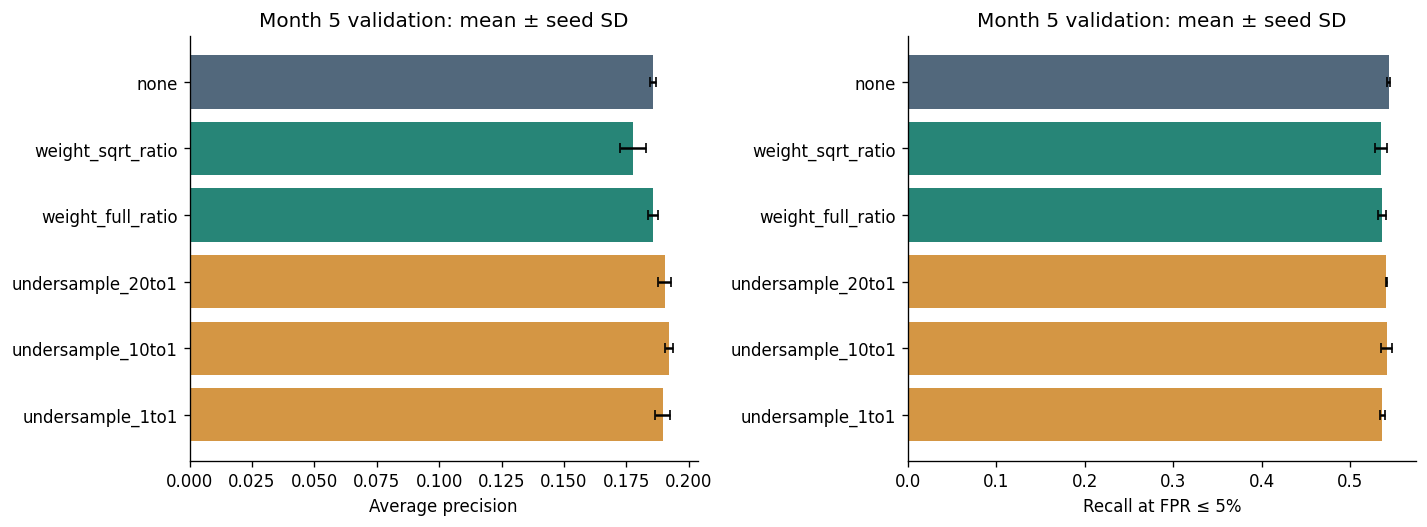

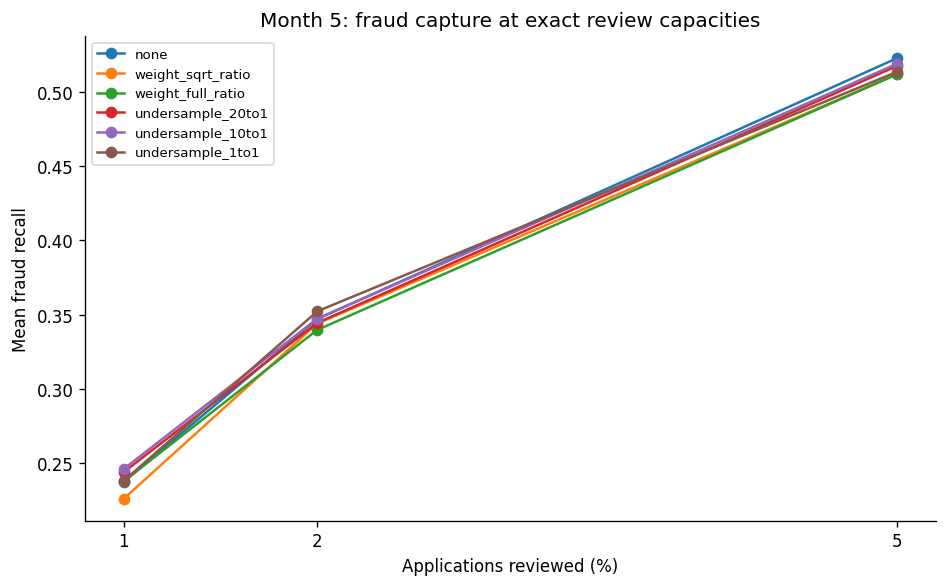

Completed results: /content/drive/MyDrive/BT4012_grp_proj/results/imbalance_treatment/imbalance_all_history_20261115T182353Z_5d20b0
Predictions / row membership / optional models: /content/drive/MyDrive/BT4012_grp_proj/artifacts/imbalance_treatment/imbalance_all_history_20261115T182353Z_5d20b0


In [ ]:
ordered = summary.set_index('condition').loc[condition_table['condition']]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
positions = np.arange(len(ordered))

for ax, mean_column, std_column, label in [
    (axes[0], 'ap_mean', 'ap_std', 'Average precision'),
    (axes[1], 'recall_at_fpr_mean', 'recall_at_fpr_std', 'Recall at FPR ≤ 5%'),
]:
    ax.barh(
        positions, ordered[mean_column],
        xerr=ordered[std_column].fillna(0), capsize=3,
        color=['#52687c' if name == 'none' else
               '#278577' if name.startswith('weight') else '#d49644'
               for name in ordered.index],
    )
    ax.set_yticks(positions, ordered.index)
    ax.invert_yaxis()
    ax.set_xlabel(label)
    ax.set_title('Month 5 validation: mean ± seed SD')

fig.tight_layout()
fig.savefig(FIGURES_DIR / 'imbalance_metrics.png', bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))

for condition in condition_table['condition']:
    frame = capacity_summary[capacity_summary['condition'] == condition]
    ax.plot(100 * frame['capacity'], frame['recall_mean'], marker='o', label=condition)

ax.set(xlabel='Applications reviewed (%)', ylabel='Mean fraud recall',
       title='Month 5: fraud capture at exact review capacities')
ax.set_xticks([100 * c for c in REVIEW_CAPACITIES])
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'imbalance_review_capacity.png', bbox_inches='tight')
plt.show()
plt.close(fig)

print('Completed results:', RESULTS_DIR)
print('Predictions / row membership / optional models:', ARTIFACTS_DIR)


## 10. Interpret results and freeze a candidate for Stage C

| Question | Evidence to record |
|---|---|
| Does weighting improve ranking? | Mean AP, paired AP differences against none, and consistency across seeds. |
| Does undersampling help despite discarding negatives? | AP / recall / runtime, retained row count, and monthly training composition. |
| Does a treatment help only at a particular review budget? | Capacity table; describe the trade-off without changing the primary criterion after seeing results. |
| Are the largest weights / balanced samples worse? | Possible loss of ranking quality under these fixed settings; do not assume balancing must help. |
| What proceeds to C? | Treatment policy and its parameters, supported by validation evidence. Keep the unweighted baseline. |

The highest mean AP is recorded in `development_ranking.json` as a development ranking, not an automatic deployment decision. Review small or seed-sensitive gains carefully. Choosing no treatment is a legitimate finding, not an unsuccessful experiment.

**Stage C:** compare the agreed bounded set of model families using all-history eligibility and the selected treatment. Recompute training-only ratios if the underlying training data changes. Different model families need their own preprocessing and validation cutoffs. Check treatment transfer for the strongest challenger rather than assuming LightGBM's result holds for every model.

**Limits:** all decisions use one validation month, so the selected validation score is optimistic. Seeds do not replace temporal replication. Fixed baseline hyperparameters may favour the unweighted reference. Undersampling changes both class composition and information retained; keep that qualification in the report. Weighted / undersampled scores are not calibrated probabilities. No test-month metrics or model selection are performed here.

**Files:** small CSVs, JSON and plots are under `results/imbalance_treatment/<run>/`. Prediction Parquets, training IDs and optional models are under `artifacts/imbalance_treatment/<run>/`. Keep large artifacts and data out of Git. Share `condition_summary.csv`, `paired_summary.csv`, `capacity_summary.csv`, `run_info.json` and the executed notebook. Confirm all 18 fits completed before interpreting aggregates.

**Business interpretation:** higher raw recall is useful only in the context of false positives and review workload. Fraud labels flagged do not establish actual fraud prevented or monetary savings. Record AI assistance according to module requirements and ensure the team understands the implementation.
